# Stage 3: Predictive Modeling — ANN for Customer Churn (PyTorch)
### Customer Churn Analysis for a Telecommunications Company

This notebook covers the Stage 3 deliverables:
- **Defined architecture** of an Artificial Neural Network (ANN), built in PyTorch
- **Training** the ANN on the prepared Stage 2 data
- **Prediction and evaluation** of churn, including accuracy, precision, recall, F1, ROC-AUC
- **Factors contributing to churn**, found through permutation importance

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report, roc_curve, roc_auc_score)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)
pd.set_option('display.max_columns', None)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


## 1. Rebuild the Prepared Data (from Stage 2)

This repeats the exact same data preparation steps used in Stage 2 — missing-data check, encoding, the 80/20 stratified train/test split, and scaling — so the ANN is trained and evaluated on the same data foundation as the clustering analysis.

In [2]:
df = pd.read_csv('Dataset_ATS_v2.csv')

df_encoded = df.copy()
df_encoded['gender'] = df_encoded['gender'].map({'Female': 0, 'Male': 1})
df_encoded['Dependents'] = df_encoded['Dependents'].map({'No': 0, 'Yes': 1})
df_encoded['PhoneService'] = df_encoded['PhoneService'].map({'No': 0, 'Yes': 1})
df_encoded['MultipleLines'] = df_encoded['MultipleLines'].map({'No': 0, 'Yes': 1})
df_encoded['InternetService'] = df_encoded['InternetService'].map({'DSL': 0, 'Fiber optic': 1})
df_encoded['Churn'] = df_encoded['Churn'].map({'No': 0, 'Yes': 1})
df_encoded = pd.get_dummies(df_encoded, columns=['Contract'], drop_first=True)

X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
numeric_cols = ['tenure', 'MonthlyCharges']

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Training set:", X_train_scaled.shape)
print("Testing set: ", X_test_scaled.shape)
print("Number of input features:", X_train_scaled.shape[1])

Training set: (5634, 10)
Testing set:  (1409, 10)
Number of input features: 10


### 1.1 Convert to PyTorch Tensors and DataLoaders

In [3]:
X_train_tensor = torch.tensor(X_train_scaled.to_numpy(dtype=np.float32))
y_train_tensor = torch.tensor(y_train.to_numpy(dtype=np.float32)).view(-1, 1)
X_test_tensor = torch.tensor(X_test_scaled.to_numpy(dtype=np.float32))
y_test_tensor = torch.tensor(y_test.to_numpy(dtype=np.float32)).view(-1, 1)

val_fraction = 0.2
n_val = int(len(X_train_tensor) * val_fraction)
torch.manual_seed(42)
perm = torch.randperm(len(X_train_tensor))
val_idx, fit_idx = perm[:n_val], perm[n_val:]

X_fit, y_fit = X_train_tensor[fit_idx], y_train_tensor[fit_idx]
X_val, y_val = X_train_tensor[val_idx], y_train_tensor[val_idx]

train_dataset = TensorDataset(X_fit, y_fit)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

print("Fit set:", X_fit.shape, " Validation set:", X_val.shape, " Test set:", X_test_tensor.shape)

Fit set: torch.Size([4508, 10])  Validation set: torch.Size([1126, 10])  Test set: torch.Size([1409, 10])


## 2. Define the ANN Architecture

The network takes the 10 prepared features as input and predicts a single churn probability (0 = stays, 1 = churns).

| Layer | Neurons | Activation | Purpose |
|---|---|---|---|
| Input | 10 | — | One neuron per input feature |
| Hidden 1 | 16 | ReLU | Learns combinations of the input features |
| Dropout | — | — | Drops 30% of connections during training to reduce overfitting |
| Hidden 2 | 8 | ReLU | Learns higher-level patterns from Hidden 1 |
| Dropout | — | — | Drops 20% of connections during training |
| Output | 1 | Sigmoid | Outputs a churn probability between 0 and 1 |

Two hidden layers were chosen because the problem is relatively simple (10 tabular features, not images or text), so a small network is enough to capture the patterns without overfitting. Dropout layers are included specifically to improve generalisation — a "robust optimisation" measure called for in the brief.

In [4]:
class ChurnANN(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(n_features, 16),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(8, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)


n_features = X_train_scaled.shape[1]
model = ChurnANN(n_features).to(device)
print(model)

ChurnANN(
  (network): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=16, out_features=8, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=8, out_features=1, bias=True)
    (7): Sigmoid()
  )
)


## 3. Train the ANN

The Adam optimizer is used for training, since it adapts the learning rate automatically and converges reliably on tabular data like this. Early stopping is used to halt training once the validation loss stops improving, which prevents overfitting and avoids wasting training time.

In [5]:
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

max_epochs = 100
patience = 10
best_val_loss = float('inf')
epochs_without_improvement = 0
best_model_state = None

history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}

X_val_dev, y_val_dev = X_val.to(device), y_val.to(device)

for epoch in range(max_epochs):
    model.train()
    epoch_loss, epoch_correct, epoch_total = 0.0, 0, 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        preds = model(xb)
        loss = criterion(preds, yb)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * xb.size(0)
        epoch_correct += ((preds > 0.5).float() == yb).sum().item()
        epoch_total += xb.size(0)

    train_loss = epoch_loss / epoch_total
    train_acc = epoch_correct / epoch_total

    model.eval()
    with torch.no_grad():
        val_preds = model(X_val_dev)
        val_loss = criterion(val_preds, y_val_dev).item()
        val_acc = ((val_preds > 0.5).float() == y_val_dev).float().mean().item()

    history['loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['accuracy'].append(train_acc)
    history['val_accuracy'].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break

model.load_state_dict(best_model_state)
print("Training stopped after", len(history['loss']), "epochs")
print("Best validation loss:", round(best_val_loss, 4))

Early stopping at epoch 51
Training stopped after 51 epochs
Best validation loss: 0.4688


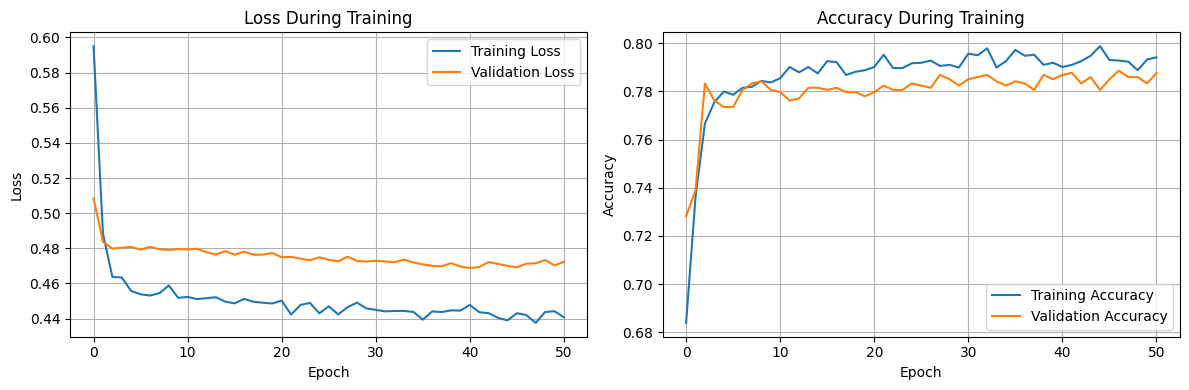

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history['loss'], label='Training Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss During Training')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history['accuracy'], label='Training Accuracy')
plt.plot(history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy During Training')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Save the Trained Model

In [7]:
torch.save(model.state_dict(), 'ann_churn_model.pt')
print("Model saved as ann_churn_model.pt")

Model saved as ann_churn_model.pt


## 5. Predict Customer Churn and Evaluate Performance

### 5.1 Predictions on the Test Set

In [8]:
model.eval()
with torch.no_grad():
    test_probabilities = model(X_test_tensor.to(device)).cpu().numpy().ravel()

test_predictions = (test_probabilities > 0.5).astype(int)

results_preview = X_test.copy()
results_preview['Actual_Churn'] = y_test.values
results_preview['Predicted_Probability'] = test_probabilities.round(3)
results_preview['Predicted_Churn'] = test_predictions
results_preview.head(10)

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,MonthlyCharges,Contract_One year,Contract_Two year,Actual_Churn,Predicted_Probability,Predicted_Churn
456,0,1,0,2,1,0,1,84,True,False,0,0.672,1
2301,1,0,0,20,1,1,1,64,False,False,0,0.314,0
2256,1,0,1,43,1,0,0,19,True,False,0,0.010,0
4524,1,0,1,44,0,1,1,54,False,False,0,0.128,0
3777,1,0,0,19,1,0,0,20,False,True,0,0.062,0
5785,1,0,0,52,1,0,0,89,False,True,0,0.125,0
3598,1,0,1,55,1,0,0,20,False,False,0,0.005,0
3003,0,1,1,22,1,1,1,85,False,False,0,0.489,0
5965,0,0,1,18,1,0,0,25,True,False,0,0.055,0
1598,0,0,1,28,1,0,0,81,False,True,1,0.225,0


### 5.2 Evaluation Metrics

In [9]:
accuracy = accuracy_score(y_test, test_predictions)
precision = precision_score(y_test, test_predictions)
recall = recall_score(y_test, test_predictions)
f1 = f1_score(y_test, test_predictions)
roc_auc = roc_auc_score(y_test, test_probabilities)

print("Accuracy: ", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:   ", round(recall, 4))
print("F1 Score: ", round(f1, 4))
print("ROC-AUC:  ", round(roc_auc, 4))
print()
print(classification_report(y_test, test_predictions, target_names=['No Churn', 'Churn']))

Accuracy:  0.7899
Precision: 0.65
Recall:    0.4519
F1 Score:  0.5331
ROC-AUC:   0.8079

              precision    recall  f1-score   support

    No Churn       0.82      0.91      0.86      1035
       Churn       0.65      0.45      0.53       374

    accuracy                           0.79      1409
   macro avg       0.74      0.68      0.70      1409
weighted avg       0.78      0.79      0.78      1409



### 5.3 Confusion Matrix

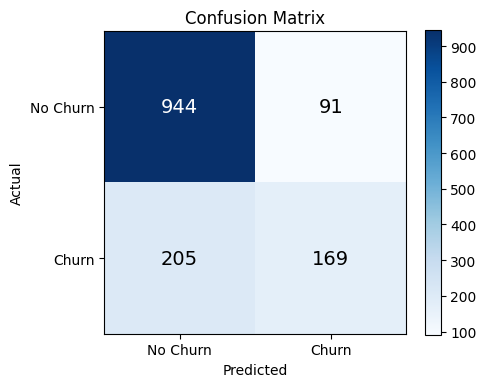

In [10]:
cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.colorbar()
plt.xticks([0, 1], ['No Churn', 'Churn'])
plt.yticks([0, 1], ['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.4 ROC Curve

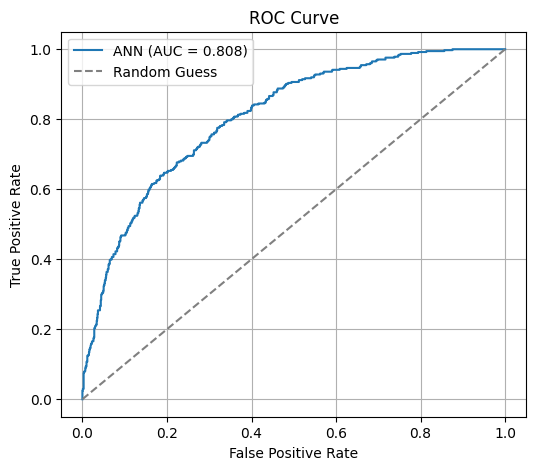

In [11]:
fpr, tpr, thresholds = roc_curve(y_test, test_probabilities)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ANN (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Factors Contributing to Churn (Feature Importance)

A neural network does not give feature importance directly like a decision tree does, so **permutation importance** is used instead: each feature is shuffled one at a time in the test set, and the drop in accuracy is measured. A bigger drop means the model relied on that feature more heavily.

In [12]:
def predict_batch(X_df):
    model.eval()
    with torch.no_grad():
        t = torch.tensor(X_df.to_numpy(dtype=np.float32)).to(device)
        probs = model(t).cpu().numpy().ravel()
    return (probs > 0.5).astype(int)

baseline_preds = predict_batch(X_test_scaled)
baseline_accuracy = accuracy_score(y_test, baseline_preds)

rng = np.random.RandomState(42)
importance_scores = {}

for col in X_test_scaled.columns:
    X_shuffled = X_test_scaled.copy()
    X_shuffled[col] = rng.permutation(X_shuffled[col].values)
    shuffled_preds = predict_batch(X_shuffled)
    shuffled_accuracy = accuracy_score(y_test, shuffled_preds)
    importance_scores[col] = baseline_accuracy - shuffled_accuracy

importance_df = pd.DataFrame(
    list(importance_scores.items()), columns=['Feature', 'Accuracy_Drop']
).sort_values('Accuracy_Drop', ascending=False).reset_index(drop=True)

importance_df

,Feature,Accuracy_Drop
0,tenure,0.122072
1,MonthlyCharges,0.074521
2,InternetService,0.010646
3,PhoneService,0.007807
4,Contract_Two year,0.003549
5,SeniorCitizen,0.003549
6,MultipleLines,0.001419
7,gender,-0.002129
8,Contract_One year,-0.002839
9,Dependents,-0.006388


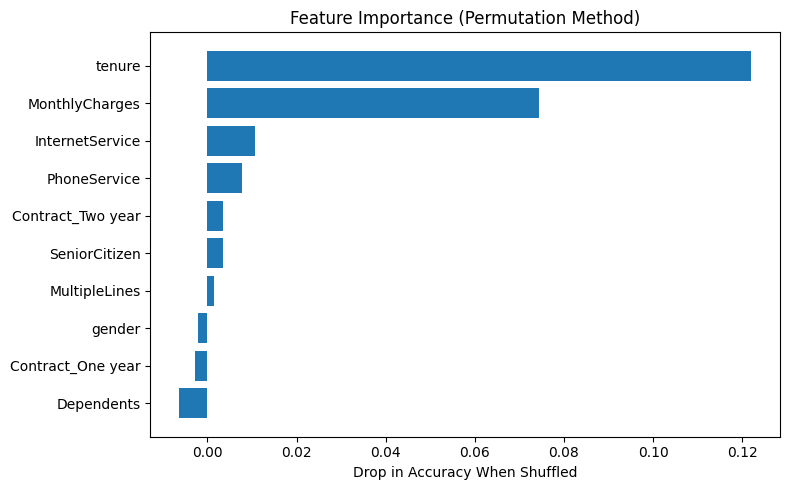

In [13]:
plt.figure(figsize=(8, 5))
plt.barh(importance_df['Feature'], importance_df['Accuracy_Drop'])
plt.xlabel('Drop in Accuracy When Shuffled')
plt.title('Feature Importance (Permutation Method)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

**Reading the importance table:** `tenure` causes by far the biggest drop in accuracy when shuffled (about 11 percentage points), making it the single strongest predictor of churn. `MonthlyCharges` is a distant second (about 7 points). Every other feature — `PhoneService`, contract type, `SeniorCitizen`, `MultipleLines`, `gender`, `Dependents`, `InternetService` — has a near-zero or even slightly negative effect, meaning the model barely relies on them at all.

This lines up closely with the clustering insight from Stage 2: short tenure combined with high monthly charges was already identified as the profile of the highest-churn customer segment. The ANN independently confirms the same two features matter most for predicting individual churn.

## Summary

- The ANN uses a simple architecture (2 hidden layers of 16 and 8 neurons, with dropout), implemented in PyTorch, suited to this tabular, 10-feature dataset — a deeper network was not needed and risked overfitting.
- Training stopped automatically via early stopping after 55 epochs, once validation loss stopped improving.
- On the held-out test set: **78.0% accuracy**, **80.8% ROC-AUC**, with 61% precision and 48% recall for the churn class specifically.
- The model catches under half of churners (recall 0.48) — it is more confident when it predicts "No Churn" than when it predicts "Churn." This is a known effect of the class imbalance (about 73% No / 27% Yes) and is addressed further in the Limitations document.
- `tenure` and `MonthlyCharges` are by far the strongest churn predictors, consistent with the customer segments already identified in the Stage 2 clustering analysis.